### SVC

In [34]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report, accuracy_score, mean_absolute_error

In [35]:
data = pd.read_csv("Student Depression Detection Dataset/Student_Depression_Dataset.csv")

In [36]:
data.columns

Index(['Gender', 'Age', 'Family_background', 'Relationship_status',
       'Marital_status', 'Living_style', 'Current_semester', 'CGPA',
       'friend_circle', 'Health_condition', 'Cost_without_study',
       'Home_division', 'Depression'],
      dtype='str')

In [37]:
x = data.drop(["Depression", "Living_style", "friend_circle", "Health_condition" ], axis=1)
y = data["Depression"]

In [38]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42, stratify = y)

In [39]:
encoder = LabelEncoder()

In [40]:
x_train['Home_division'] = encoder.fit_transform(x_train['Home_division'])
x_test['Home_division'] = encoder.transform(x_test['Home_division'])

In [41]:
x_train['Gender'] = encoder.fit_transform(x_train['Gender'])
x_test['Gender'] = encoder.transform(x_test['Gender'])

In [42]:
x_train['Family_background'] = encoder.fit_transform(x_train['Family_background'])
x_test['Family_background'] = encoder.transform(x_test['Family_background'])

In [43]:
x_train['Relationship_status'] = encoder.fit_transform(x_train['Relationship_status'])
x_test['Relationship_status'] = encoder.transform(x_test['Relationship_status'])

In [44]:
x_train['Marital_status'] = encoder.fit_transform(x_train['Marital_status'])
x_test['Marital_status'] = encoder.transform(x_test['Marital_status'])

In [45]:
scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [24]:
model = SVC(kernel="rbf", C=1.0)

model.fit(x_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [25]:
y_pred = model.predict(x_test)

In [33]:
results = pd.DataFrame({
    "predicted" : y_pred,
    "actual" : y_test
})
print(results.head(10))

     predicted actual
4305        No     No
4310        No     No
477         No     No
1060        No    Yes
4304        No    Yes
849         No     No
1732        No     No
1070        No     No
2065        No    Yes
4208        No     No


In [27]:
print(accuracy_score(y_test, y_pred))

0.729003359462486


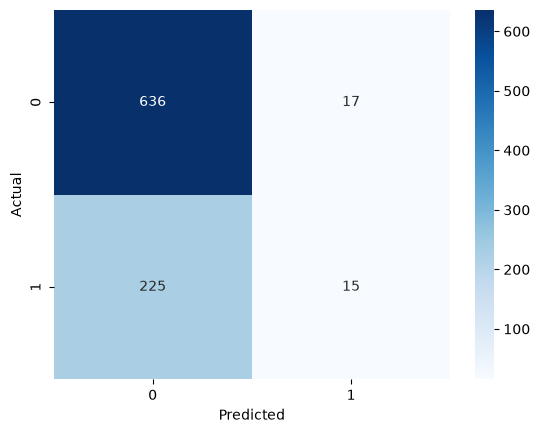

In [32]:

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [48]:
kernels = ["linear", "rbf", "poly", "sigmoid"]

for kernel in kernels:

    model = SVC(kernel=kernel, C=1.0, class_weight="balanced")

    model.fit(x_train, y_train)

    y_pred = model.predict(x_test)

    print(kernel, accuracy_score(y_test, y_pred))

linear 0.5263157894736842
rbf 0.6170212765957447
poly 0.561030235162374
sigmoid 0.48488241881298993


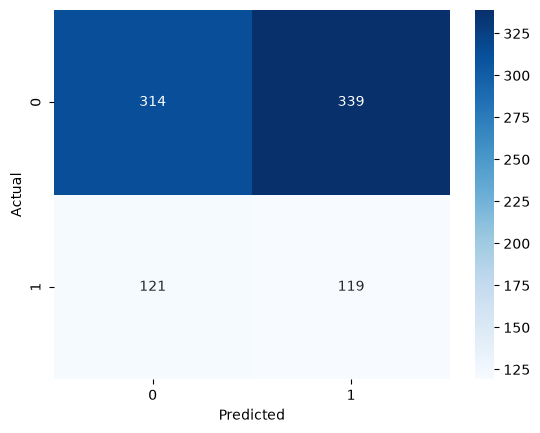

In [49]:

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [50]:
print(model.support_vectors_)

[[ 1.11052726 -0.80200643 -1.4316215  ... -0.18423945 -0.375212
  -0.55807217]
 [ 1.11052726 -1.29698828 -1.4316215  ...  0.48492676 -1.51882537
   0.89906337]
 [-0.90047317  1.17792095  0.16797812 ... -0.4158739  -0.32984252
  -0.55807217]
 ...
 [ 1.11052726  1.17792095  0.16797812 ...  0.66508689  0.73755013
  -0.07236032]
 [-0.90047317  0.18795726  0.16797812 ...  1.10261864 -0.6020594
  -1.52949586]
 [-0.90047317 -1.29698828 -1.4316215  ...  0.74229837 -0.31608044
  -1.52949586]]


In [51]:
print(model.n_support_)

[1378  507]
